In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
project_root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / ".env").exists()
)
PROCESSED_DIR = project_root / "data" / "processed"
RESULTS_DIR = project_root / "results"

In [3]:
df = pd.read_csv(
    PROCESSED_DIR / "btc_spy_daily.csv",
    index_col="date",
    parse_dates=True
)

In [4]:
year_end_prices = df.resample("YE").last()
year_end_prices

,price_btc,price_spy
date,,
2013-12-31,754.010000,149.261826
2014-12-31,319.983000,169.358170
2015-12-31,430.538000,171.448532
2016-12-31,961.107000,192.018723
2017-12-31,14598.572319,233.697174
2018-12-31,3746.123953,223.019562
2019-12-31,7202.624251,292.654938
2020-12-31,28977.961818,346.303314
2021-12-31,46304.949594,445.791901


In [7]:
year_end_prices["pct_change_btc"] = year_end_prices["price_btc"].pct_change() * 100.0
year_end_prices["pct_change_spy"] = year_end_prices["price_spy"].pct_change() * 100.0
year_end_prices

,price_btc,price_spy,pct_change_btc,pct_change_spy
date,,,,
2013-12-31,754.010000,149.261826,NaN,NaN
2014-12-31,319.983000,169.358170,-57.562499,13.463820
2015-12-31,430.538000,171.448532,34.550273,1.234285
2016-12-31,961.107000,192.018723,123.233954,11.997881
2017-12-31,14598.572319,233.697174,1418.933097,21.705410
2018-12-31,3746.123953,223.019562,-74.339107,-4.568995
2019-12-31,7202.624251,292.654938,92.268711,31.223887
2020-12-31,28977.961818,346.303314,302.325053,18.331615
2021-12-31,46304.949594,445.791901,59.793673,28.728742


In [14]:
annual_returns = year_end_prices[["pct_change_btc", "pct_change_spy"]].copy()
annual_returns = annual_returns.rename(
    columns={"pct_change_btc": "BTC", "pct_change_spy": "SPY"}
)
annual_returns.style.format("{:,.2f}%")

,BTC,SPY
date,,
2013-12-31 00:00:00,nan%,nan%
2014-12-31 00:00:00,-57.56%,13.46%
2015-12-31 00:00:00,34.55%,1.23%
2016-12-31 00:00:00,123.23%,12.00%
2017-12-31 00:00:00,"1,418.93%",21.71%
2018-12-31 00:00:00,-74.34%,-4.57%
2019-12-31 00:00:00,92.27%,31.22%
2020-12-31 00:00:00,302.33%,18.33%
2021-12-31 00:00:00,59.79%,28.73%


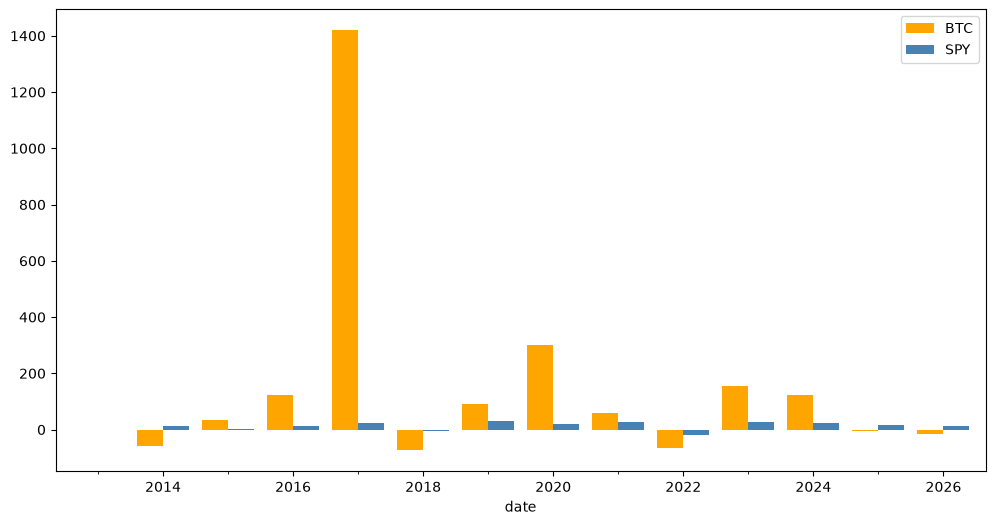

In [15]:
ax = annual_returns.plot.bar(
    figsize=(12, 6),
    color=["orange", "steelblue"],
    width=0.8,
)

In [16]:
year_labels = annual_returns.index.year.astype(str).tolist()
year_labels[-1] = "2026 YTD"

ax.set_xticklabels(year_labels, rotation=45, ha="right")

/var/folders/5l/hjjdz2n16yj_q0n4tmtphndr0000gn/T/ipykernel_88399/2235985607.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(year_labels, rotation=45, ha="right")


[Text(42, 0, '2013'),
 Text(44, 0, '2014'),
 Text(46, 0, '2015'),
 Text(48, 0, '2016'),
 Text(50, 0, '2017'),
 Text(52, 0, '2018'),
 Text(54, 0, '2019'),
 Text(56, 0, '2020')]

In [17]:
ax.set_title("Annual returns: BTC vs SPY (2026 through November 12)")
ax.set_xlabel("Year")
ax.set_ylabel("Return (%)")
ax.axhline(0, color="black", linewidth=0.8)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

In [18]:
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "annual_returns.png", dpi=300)
plt.show()

In [19]:
ax.set_yscale("symlog", linthresh=10)
ax.set_ylabel("Return (%, symmetric log scale)")

Text(88.00976562500004, 0.5, 'Return (%, symmetric log scale)')

In [20]:
ticks = [-100, -50, -10, 0, 10, 50, 100, 500, 1500]
ax.set_yticks(ticks)
ax.set_yticklabels([f"{value:,}%" for value in ticks])

[Text(0, -100, '-100%'),
 Text(0, -50, '-50%'),
 Text(0, -10, '-10%'),
 Text(0, 0, '0%'),
 Text(0, 10, '10%'),
 Text(0, 50, '50%'),
 Text(0, 100, '100%'),
 Text(0, 500, '500%'),
 Text(0, 1500, '1,500%')]

In [21]:
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "annual_returns_symlog.png", dpi=300)
plt.show()

In [22]:
month_end_prices = df.resample("ME").last()

In [24]:
monthly_returns = month_end_prices.pct_change(fill_method=None) * 100

In [25]:
monthly_returns = monthly_returns.rename(
    columns={"price_btc": "BTC", "price_spy": "SPY"}
)
monthly_returns = monthly_returns.dropna(how="all")

In [26]:
last_month = df.index[-1].to_period("M")
complete_months = monthly_returns.index.to_period("M") < last_month

complete_monthly_returns = monthly_returns.loc[complete_months].copy()

In [27]:
display(complete_monthly_returns.head())
display(complete_monthly_returns.tail())
print("Complete months:", len(complete_monthly_returns))

,BTC,SPY
date,,
2014-01-31,10.067506,-3.524813
2014-02-28,-33.817717,4.551613
2014-03-31,-16.796963,0.829542
2014-04-30,-2.047260,0.695101
2014-05-31,37.458254,2.320665


,BTC,SPY
date,,
2026-06-30,-20.231012,-1.029258
2026-07-31,7.350788,0.034822
2026-08-31,25.048332,2.679936
2026-09-30,6.355939,-0.329342
2026-10-31,-7.630463,-0.906080


Complete months: 154


In [30]:
monthly_summary = pd.DataFrame({
    "Mean return": complete_monthly_returns.mean(),
    "Median return": complete_monthly_returns.median(),
    "Best month": complete_monthly_returns.max(),
    "Worst month": complete_monthly_returns.min(),
})
monthly_summary.style.format("{:,.2f}%")

,Mean return,Median return,Best month,Worst month
BTC,5.10%,3.02%,73.83%,-38.24%
SPY,1.15%,1.60%,12.70%,-12.49%


In [31]:
monthly_summary["Positive months"] = (
    complete_monthly_returns.gt(0).mean() * 100
)

In [32]:
monthly_gap = (
    complete_monthly_returns["BTC"]
    - complete_monthly_returns["SPY"]
)

In [ ]:
comparison_summary = pd.DataFrame({
    "Value": [
        monthly_gap.gt(0).mean() * 100,
        monthly_gap.lt(0).mean() * 100,
        monthly_gap.eq(0).mean() * 100,
        monthly_gap.mean(),
    ],
    "Unit": ["% of months", "% of months", "% of months", "percentage points"],
}, index=["BTC outperformed", "SPY outperformed", "Tied", "Mean BTC minus SPY return"])

period_start = complete_monthly_returns.index[0].strftime("%B %Y")
period_end = complete_monthly_returns.index[-1].strftime("%B %Y")
period_label = f"{period_start}–{period_end} | {len(complete_monthly_returns)} complete months"

asset_table = monthly_summary.style.format("{:,.2f}%").set_caption(period_label)
comparison_table = comparison_summary.style.format({"Value": "{:,.2f}"})
display(asset_table)
display(comparison_table)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
monthly_summary.to_csv(RESULTS_DIR / "monthly_performance_summary.csv", index_label="Asset")
comparison_summary.to_csv(RESULTS_DIR / "monthly_comparison_summary.csv", index_label="Metric")

report_html = (
    '<!doctype html><html><head><meta charset="utf-8"><title>Monthly performance</title>'
    '<style>body{font-family:system-ui;max-width:1000px;margin:40px auto;padding:0 20px;}'
    'table{border-collapse:collapse;margin:20px 0;}th,td{padding:9px 14px;'
    'border-bottom:1px solid #ddd;text-align:right;}caption{text-align:left;padding:8px 0;}'
    '</style></head><body><h1>BTC vs SPY: monthly performance</h1>'
    + asset_table.to_html() + comparison_table.to_html()
    + '<p>Returns use the last shared trading date of each month. '
    'The final partial month is excluded. Mean returns are arithmetic monthly averages, '
    'not annualized returns. The return gap is measured in percentage points.</p></body></html>'
)
report_path = RESULTS_DIR / "monthly_performance_report.html"
report_path.write_text(report_html, encoding="utf-8")
print(f"Saved two summary CSVs and {report_path.name} to {RESULTS_DIR}")
